## Материалы
* Презентация (https://drive.google.com/file/d/1FHXmUzYO5zXYrp4vRhvssWUH8ic75PoT/view?usp=share_link)
* Дашборд (https://public.tableau.com/views/_16798417356810/Dashboard1?:language=en-US&:display_count=n&:origin=viz_share_link)

# Сегментация пользователей банка

**Описание проекта**

Заказчик - менеджер продуктов банка. Необходимо проанализировать клиентов регионального банка «Метанпромбанк» и сегментировать пользователей по кол-ву потребляемых продуктов. Анализ покажет, как клиенты пользуются услугами банка, а так же поможет составить портрет клиентов, которые склонны уходить из банка.

**Цель проекта** - анализ оттока клиентов банка и формулировка рекомендации по удержанию сегментов пользователей.

**Описание данных**

Датасет содержит данные о клиентах банка «Метанпром». Банк располагается в Ярославле и областных городах: Ростов Великий и Рыбинск.

- `userid` — идентификатор пользователя,
- `score` — баллы кредитного скоринга,
- `City` — город,
- `Gender` — пол,
- `Age` — возраст,
- `Objects` — количество объектов в собственности,
- `Balance` — баланс на счёте,
- `Products` — количество продуктов, которыми пользуется клиент,
- `CreditCard` — есть ли кредитная карта,
- `Loyalty` — активный клиент,
- `estimated_salary` — заработная плата клиента,
- `Churn` — ушёл или нет.

**План работы**

1. Загрузка данных/библиотек и первичное знакомство
   - Загрузить библиотеки и данные, посмотреть на датасет и основную информацию о нем
2. Предобработка данных
    - Проверить корректность наименований колонок и исследовать дубликаты, пропущенные значения, соответствие типов;
    - При необходимости: переименовать колонки, удалить дубликаты, привести типы и заменить пропущенные значения.
3. Исследовательский анализ данных
    - Посмотреть данные со всех сторон и по всем признакам, чтобы получить общее понимание о них (общее кол-во, среднее/медианное значения, распределение, выбросы и тп.)
4. Сегментация
    - Сегментровать пользователей на основе данных о кол-ве потребляемых продуктов и доли оттока 
5. Статистическая проверка гипотез
    - Сформулировать и проверить статистические гипотезы: Проверить гипотезу различия дохода между теми клиентами, которые пользуются двумя продуктами банка, и теми, которые пользуются одним. Сформулировать и проверить вторую статистическую гипотезу относительно представленных данных.
6. Выводы и рекомендации
    - Сделать выводы и дать рекомендации по удержанию сегментов пользователей банка

## 1. Загрузка данных/библиотек и первичное знакомство

In [1]:
# импорт библиотек
import pandas as pd

from scipy import stats as st
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
from plotly import graph_objects as go

In [2]:
# открываем и сохраняем файл с данными
try:
    df = pd.read_csv('/datasets/bank_dataset.csv')
except:
    df = pd.read_csv('bank_dataset.csv')
    
df.head()

,userid,score,City,Gender,Age,Objects,Balance,Products,CreditCard,Loyalty,estimated_salary,Churn
0,15677338,619,Ярославль,Ж,42,2,NaN,1,1,1,101348.88,1
1,15690047,608,Рыбинск,Ж,41,1,83807.86,1,0,1,112542.58,0
2,15662040,502,Ярославль,Ж,42,8,159660.80,3,1,0,113931.57,1
3,15744090,699,Ярославль,Ж,39,1,NaN,2,0,0,93826.63,0
4,15780624,850,Рыбинск,Ж,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# выведим основную информацию
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   userid            10000 non-null  int64  
 1   score             10000 non-null  int64  
 2   City              10000 non-null  object 
 3   Gender            10000 non-null  object 
 4   Age               10000 non-null  int64  
 5   Objects           10000 non-null  int64  
 6   Balance           6383 non-null   float64
 7   Products          10000 non-null  int64  
 8   CreditCard        10000 non-null  int64  
 9   Loyalty           10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  Churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [4]:
# смотрим описательную статистику
df.describe()

,userid,score,Age,Objects,Balance,Products,CreditCard,Loyalty,estimated_salary,Churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,6383.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.573368e+07,650.528800,38.921800,5.012800,119827.493793,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,30095.056462,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.560844e+07,350.000000,18.000000,0.000000,3768.690000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.567126e+07,584.000000,32.000000,3.000000,100181.975000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.573347e+07,652.000000,37.000000,5.000000,119839.690000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.579597e+07,718.000000,44.000000,7.000000,139512.290000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.585843e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


### Вывод

Загружен датасет, кол-во строк 10000 и 12 столбцов, в столбце `Balance` есть пропущенные значения. Данные содержат 3 типа: object, int64, float64, типы данных везде соответствуют.

## 2. Предобработка данных

### Переименование столбцов и приведение из к единому стилю

In [5]:
# приведем столбцы к нижнему регистру
df.columns = df.columns.str.lower()

In [6]:
# переименуем столбцы
df = df.rename(columns={'userid':'user_id', 'creditcard':'credit_card'})

In [7]:
# в столбце 'gender' изменим значения на числовые для дальнейшего анализа
df['gender'] = df['gender'].map({'М':1, 'Ж':0})

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           10000 non-null  int64  
 1   score             10000 non-null  int64  
 2   city              10000 non-null  object 
 3   gender            10000 non-null  int64  
 4   age               10000 non-null  int64  
 5   objects           10000 non-null  int64  
 6   balance           6383 non-null   float64
 7   products          10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   loyalty           10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(9), object(1)
memory usage: 937.6+ KB


### Проверка на наличие дубликатов 

In [9]:
# проверяем на наличие дубликатов
df.duplicated().sum()

0

Явных дубликатов нет, проверим категориальные значения на наличие неявных дубликатов

In [10]:
len(df['city'])

10000

In [11]:
df['city'].str.lower().value_counts()

ярославль         5014
ростов великий    2509
рыбинск           2477
Name: city, dtype: int64

В столбце 'city' все в порядке. Посомотрим дубликаты в столбце 'user_id' и и без него

In [12]:
df['user_id'].nunique()

10000

In [13]:
df_no_id = df.drop(columns = 'user_id')
df_no_id.duplicated().sum()

0

Дубликатов не обнаружено

### Проверка на наличие пропусков 

In [14]:
# проверяем кол-во пропусков
df.isna().sum()

user_id                0
score                  0
city                   0
gender                 0
age                    0
objects                0
balance             3617
products               0
credit_card            0
loyalty                0
estimated_salary       0
churn                  0
dtype: int64

В столбце balance 36% пропусков, это много, поэтому удалить мы их не можем. Посмотрим на пропуски в разрезе остальных признаков

In [15]:
# смотрим распределение пропусков по каждому признаку
temp = df[df['balance'].isna()] 
list_c = ['city', 'objects', 'products', 'credit_card', 'loyalty', 'churn']
for c in list_c:
    print('-'* 25)
    print('Кол-во значений:', c)
    print(temp[c].value_counts())

-------------------------
Кол-во значений: city
Ярославль    2418
Рыбинск      1199
Name: city, dtype: int64
-------------------------
Кол-во значений: objects
7     386
2     382
5     374
4     369
6     367
8     363
9     360
3     352
1     349
10    178
0     137
Name: objects, dtype: int64
-------------------------
Кол-во значений: products
2    2600
1     905
3      98
4      14
Name: products, dtype: int64
-------------------------
Кол-во значений: credit_card
1    2592
0    1025
Name: credit_card, dtype: int64
-------------------------
Кол-во значений: loyalty
1    1873
0    1744
Name: loyalty, dtype: int64
-------------------------
Кол-во значений: churn
0    3117
1     500
Name: churn, dtype: int64


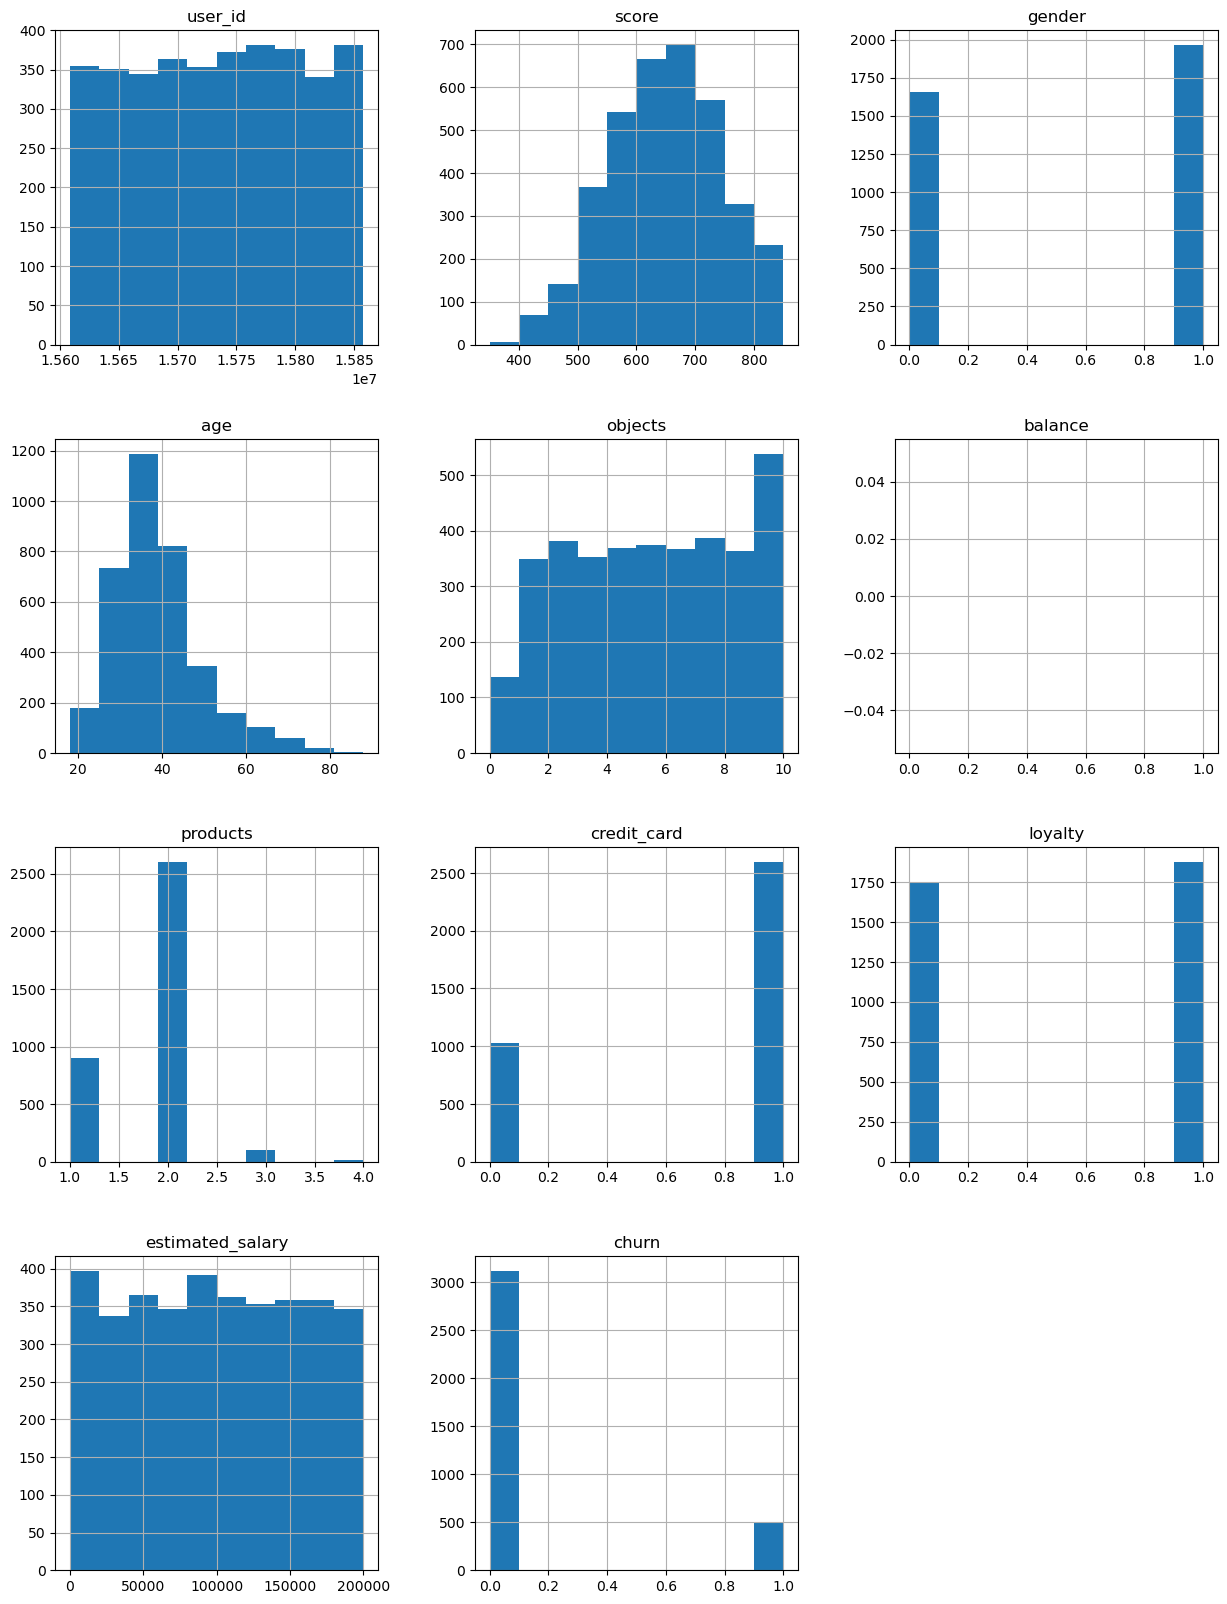

In [16]:
# строим общую гистограмму для всех числовых столбцов таблицы с пропусками
temp.hist(figsize=(15, 20));

In [17]:
# проверяем, есть ли нулевые значения в поле `balance`
len(df.query('balance == 0'))

0

- Пропуски данных есть только в Рыбинске и Ярославле, в Ростове пропусков нет. 
- Также пропуски есть как у ушедших, так и оставшихся в банке клиентов, т.е. пропуск не является признаком оттока. 
- Нет зависимости наличия пропуска от какого-либо другого признака.
- Нулевых значений в датасете нет, что скорее всего говорит о том, что пропуски - это нулевые значения.

**В результате анализа** вероятной причиной пропусков в столбце `balance` скорее всего ошибка в загрузке данных. Поэтому, чтобы не исказить анализ, не удаляем строки с пропусками (т.к.это 36% датасета), и не заменяем пропуски на нули (т.к.это исказит данные при дальнейшем анализе).

In [18]:
# смотрим на распределение баланса, заработной платы клиентов и баллов кредитного скоринга
def box (data, c_list):
    for col in c_list:
        plt.figure(figsize=(15,2))
        sns.set_style('whitegrid')
        sns.boxplot(data=data, x=col, palette='Purples');
        plt.title(f'Распределение по признаку {col}', fontsize = 12)
        plt.xlabel(' ')
        plt.show()

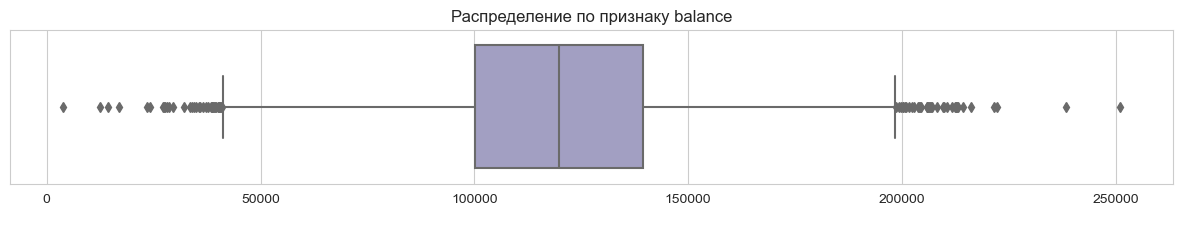

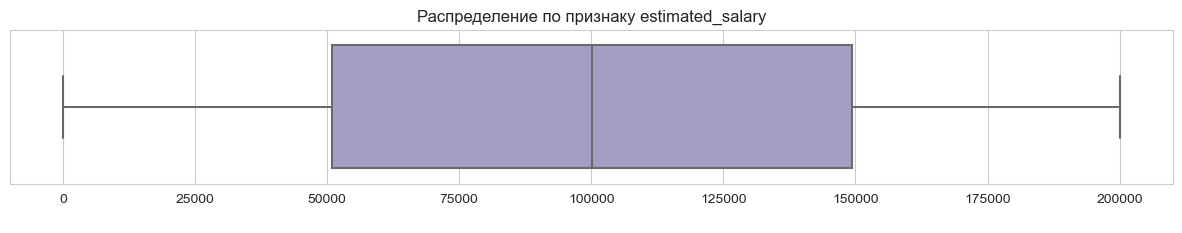

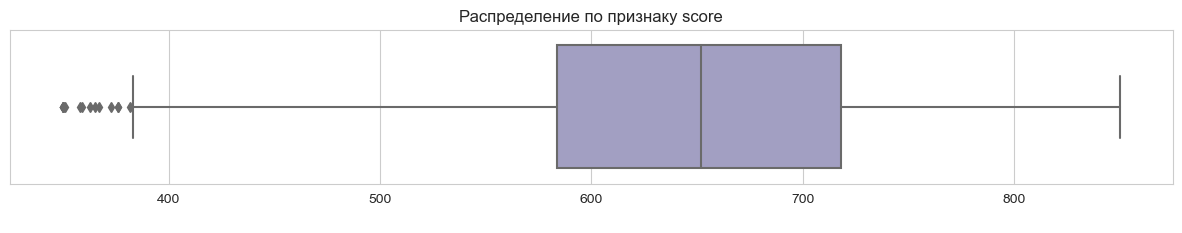

In [19]:
c_list = ['balance', 'estimated_salary', 'score']
box(df, c_list)

Данные распределены нормально. В `estimated_salary`симметричное распределение, среднее на отметке 100 000, выбросы отсутствуют. В `score`среднее значение - 650 ед. и небольшие выбросы в меньшую сторону, кажется не слишком критичны для нас. Выбросы в `balance` могут быть связаны с большой разницей дохода и соответственно большими или маленькими балансом на банковском счете. Оставляем все как есть.

### Вывод

- столбцы приведены к нижнему регистру и переименованы для удобства 
- проведена замена значений поля `gender` с М/Ж на 1 и 0 соответственно
- дубликатов не было выялено
- пропуски присутсвуют в поле `balance`, но приянто решение их оставить, чтобы избежать искажения анализа

## 3. Исследовательский анализ данных (EDA)

### Общее распределение признаков

In [20]:
# смотрим общее распределение 
df.describe()

,user_id,score,gender,age,objects,balance,products,credit_card,loyalty,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,6383.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.573368e+07,650.528800,0.545700,38.921800,5.012800,119827.493793,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,0.497932,10.487806,2.892174,30095.056462,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.560844e+07,350.000000,0.000000,18.000000,0.000000,3768.690000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.567126e+07,584.000000,0.000000,32.000000,3.000000,100181.975000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.573347e+07,652.000000,1.000000,37.000000,5.000000,119839.690000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.579597e+07,718.000000,1.000000,44.000000,7.000000,139512.290000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.585843e+07,850.000000,1.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [21]:
# функция для графиков распределения:

def graf (data, d_list, c_list, hue=None):
    
    plt.subplots(figsize=(5, 5))
    
    # дискретные значения
    for col in d_list:
        sns.countplot(data=data, x=col, hue=hue, palette='coolwarm');
        plt.title(f'Распределение по признаку {col}', fontsize = 12)
        plt.ylabel('Кол-во значений')
        plt.show()

    # непрерывные значения
    for col in c_list:
        sns.histplot(data=data, x=col, hue=hue, kde=True, color="darkblue");
        plt.title(f'Распределение по признаку {col}', fontsize = 12)
        plt.ylabel('Кол-во значений')
        plt.show()

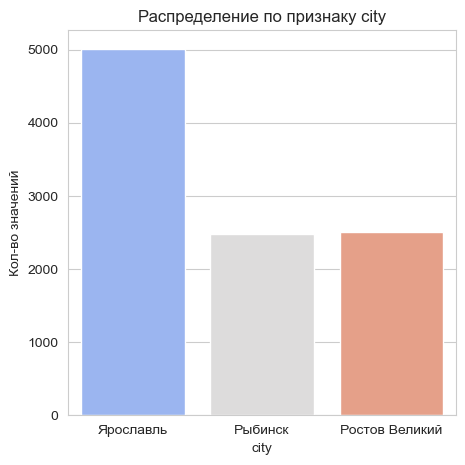

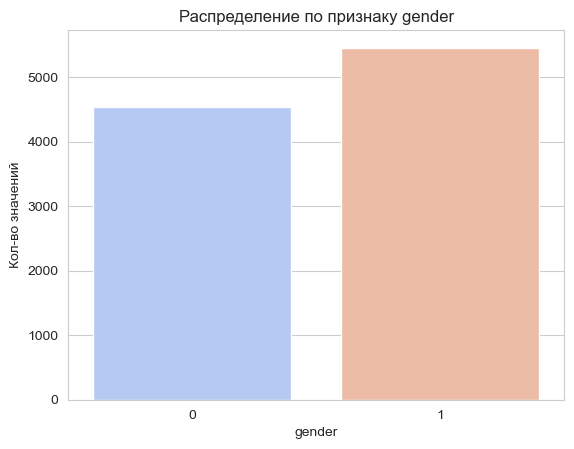

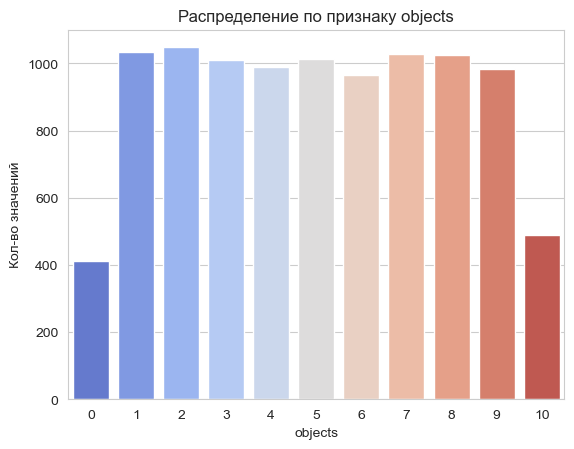

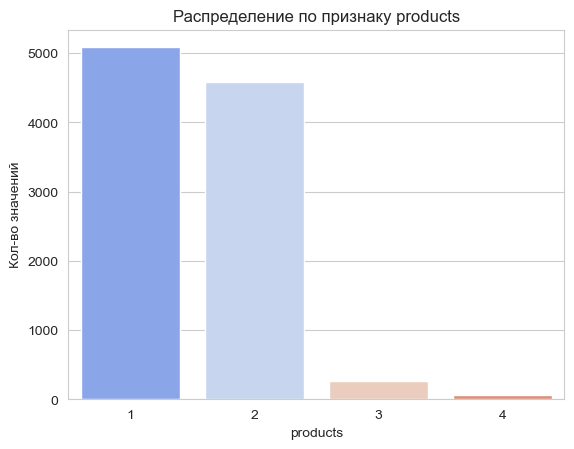

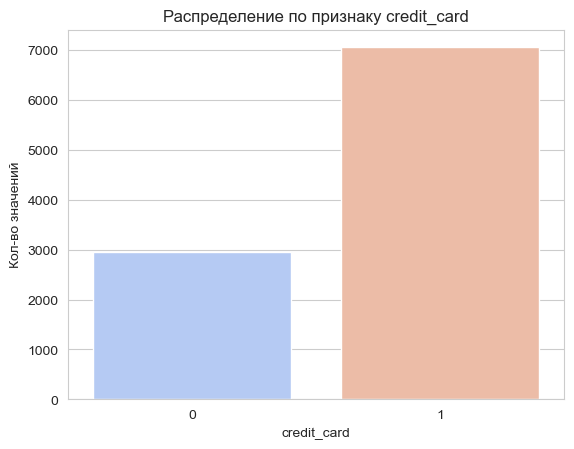

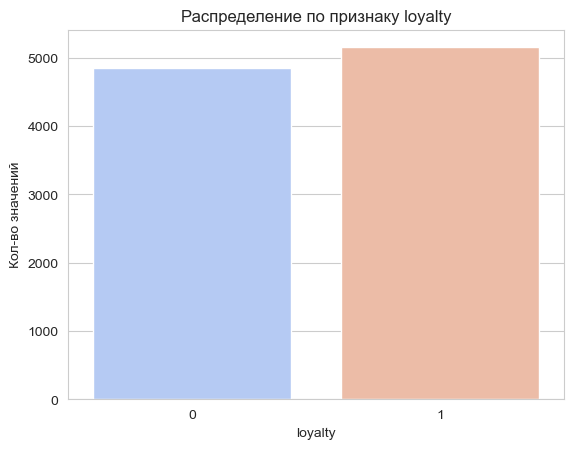

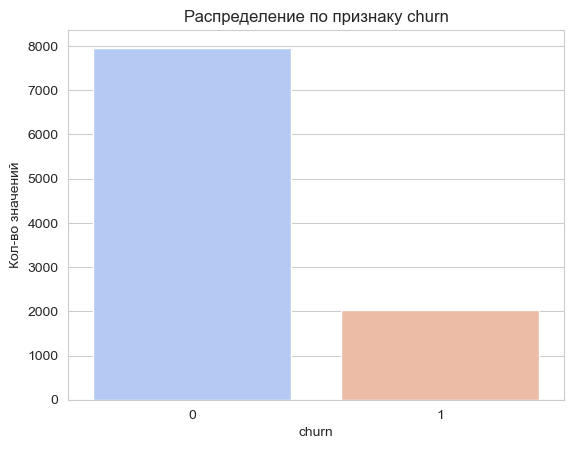

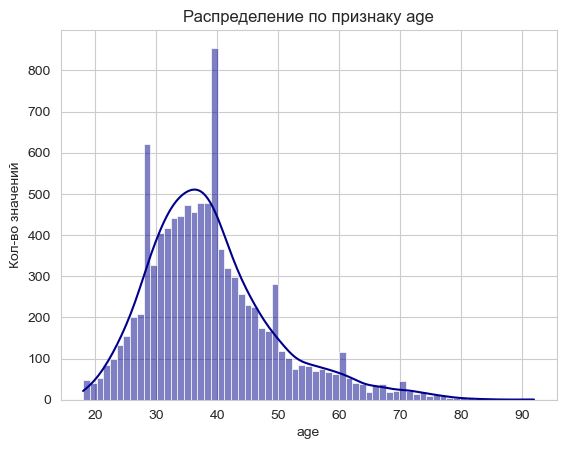

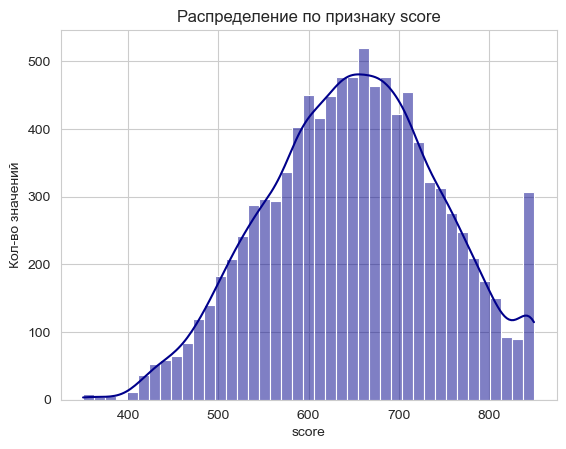

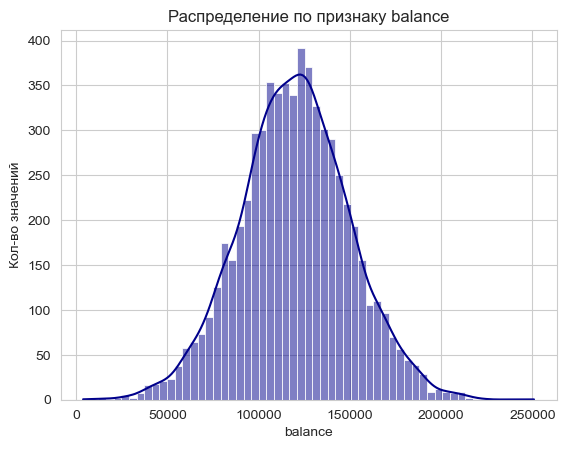

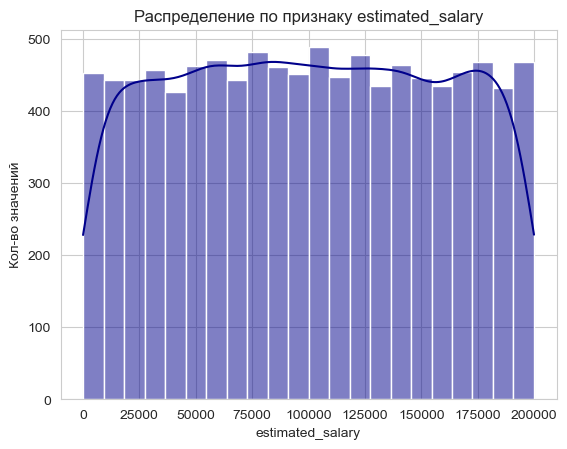

In [22]:
# визуализация
d_list = ['city', 'gender', 'objects', 'products', 'credit_card', 'loyalty', 'churn']
c_list = ['age', 'score',  'balance', 'estimated_salary']
graf(df, d_list, c_list, hue=None) 

Странно вяглядит распределение признаков `objects` и `estimated_salary`: небольшие значения почти отсутствуют, в середине плато.

Самый большой филиал находится в Ярославле. Из остальных признаков можем составить обобщенный портрет клиента банка: небольшой перевес в сторону мужчин, возраст 37-38 лет с 5-ю объектами недвижимости в среднем, со средним остатком на счетах 120 тыс.у.е. и средним доходом в 100 тыс.у.е.,пользуется 1-2 продуктами, чаще есть кредитная карта. Активных и неактивных клиентов примерно попровну, а вероятность ухода клиентов - 20%.

### Матрица корреляций

In [23]:
# кодируем признак city для расчета корреляции
df1 = pd.get_dummies(df, columns=['city'])

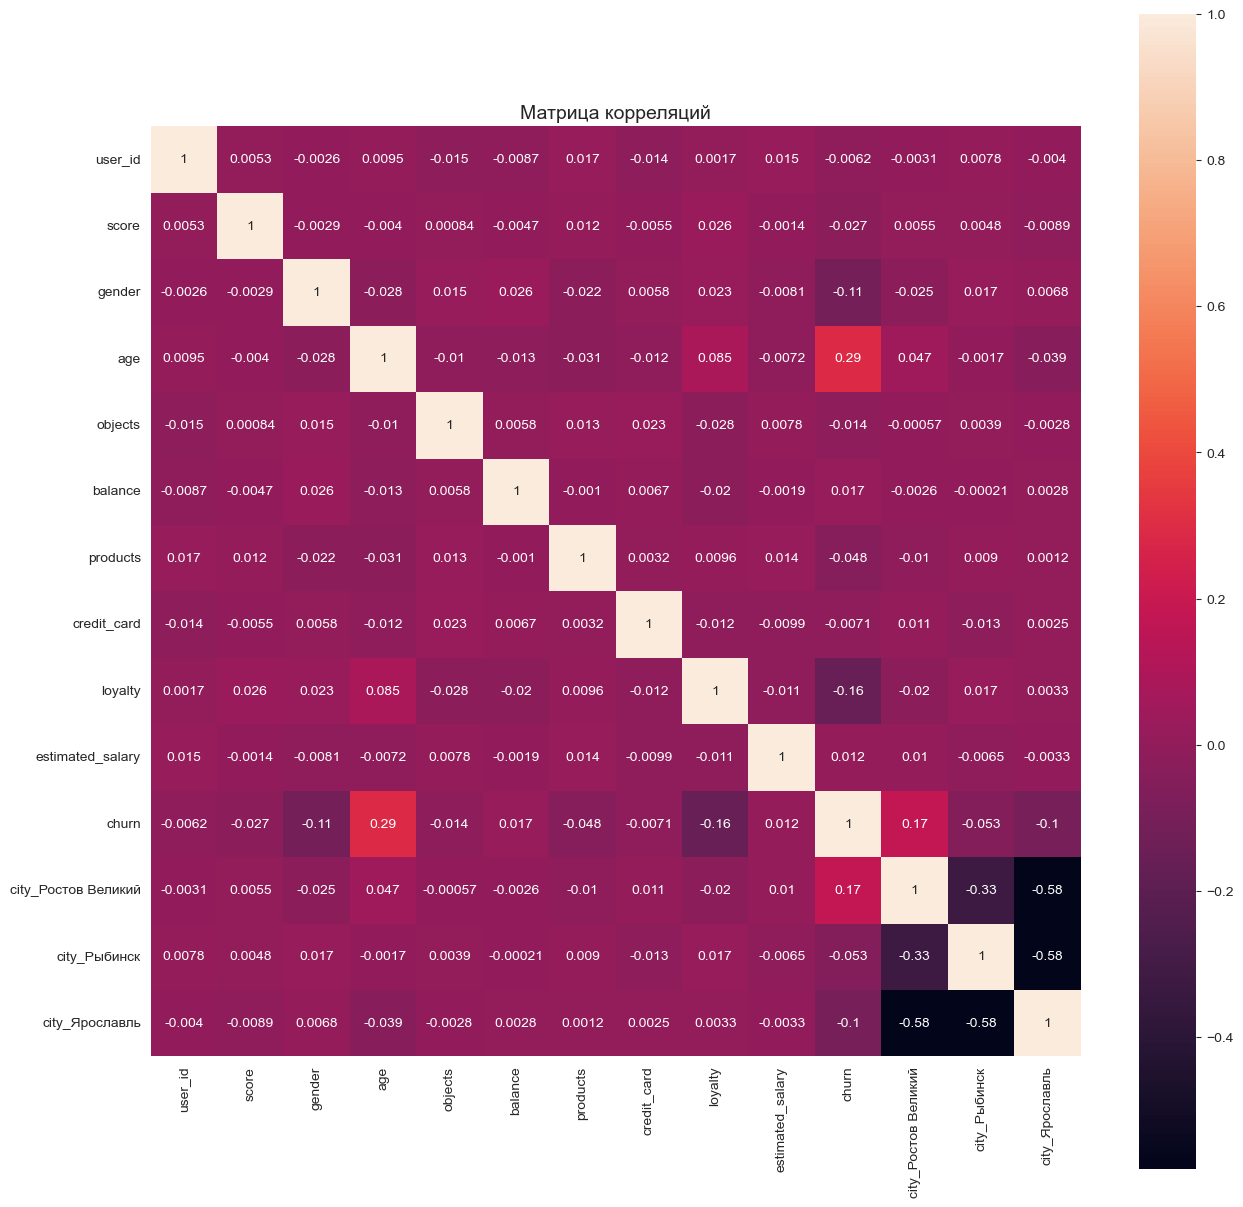

In [24]:
# визуализация
# вычисляем корреляции
temp = df1.corr() 

plt.figure(figsize=(15,15))

sns.heatmap(temp, annot=True, square=True)

plt.title('Матрица корреляций', fontsize = 14)
plt.show()

Признаки не коррелируют между собой, макисмальная корреляция очень слабая (0.29). С целевой переменной `churn` больше всего коррелирует `age` и`city_Ростов Великий`

### Вывод

- Самый большой филиал в Ярославле
- Портрет клиента банка: чаще мужчина, возраст 37-38 лет с 5-ю объектами недвижимости, со средним остатком 120 тыс.у.е. и средним доходом 100 тыс.у.е.,пользуется 1-2 продуктами, есть кредитная карта
- Доля оттока 20% от общего кол-ва пользователей
- Корреляция между признаки очень слабая

## 4. Сегментация

Для решения поставленной цели проекта, необходимо сегментировать пользователей по кол-ву потребляемых продуктов, обращая внимание на отток. 

### Категоризация данных по возрасту 

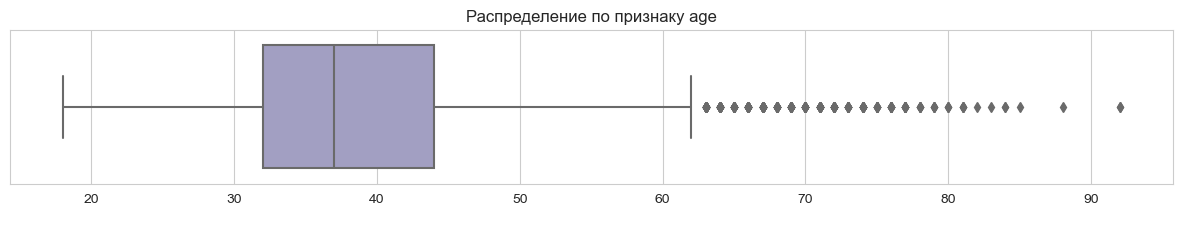

In [25]:
# смотрим на распределение и выбросы в признаке 'age'
c_list = ['age']
box(df, c_list)

Видим, что средний возраст клиентов примерно равен 37-38 лет, также есть выбросы в большую сторону. Эти выбросы - пожилые клиенты банка.

На основании распределения по возрасту проведем категоризацию на возрастные группы:
- младше 25 лет;
- от 26 до 35 лет;
- от 36 до 45 лет;
- от 46 до 60 лет;
- старше 60 лет.

In [26]:
# категоризуем на возрастные группы
def age_group (age):
    if age < 25:
        return '< 25'
    elif age < 35:
        return '26-35'
    elif age < 45:
        return '36-45'
    elif age < 60:
        return '46-60'
    else:
        return '> 60'

# применим функцию к датафрейму
df['age_group'] = df['age'].apply(age_group)

df.head()

,user_id,score,city,gender,age,objects,balance,products,credit_card,loyalty,estimated_salary,churn,age_group
0,15677338,619,Ярославль,0,42,2,NaN,1,1,1,101348.88,1,36-45
1,15690047,608,Рыбинск,0,41,1,83807.86,1,0,1,112542.58,0,36-45
2,15662040,502,Ярославль,0,42,8,159660.80,3,1,0,113931.57,1,36-45
3,15744090,699,Ярославль,0,39,1,NaN,2,0,0,93826.63,0,36-45
4,15780624,850,Рыбинск,0,43,2,125510.82,1,1,1,79084.10,0,36-45


### Сегментация по кол-ву продуктов

Делим данные на 4 сегмента в соответствии с кол-вом продуктов банка - признак `products`.

In [27]:
df['products'].value_counts()

1    5084
2    4590
3     266
4      60
Name: products, dtype: int64

Из предыдущего анализа видно, что чаще клиенты пользуются одним или двумя продуктами, а 3 и 4 продуктами практически не интересуются. Так как группы с 3 и 4 продуктами малочисленны, укрупним сегменты - объеденим 3 и 4 продукты в один и разделим клиентов на 3 сегмента

In [28]:
# добавим столбец с сегментами
df['segments'] = df['products'].replace(4, 3)

In [29]:
# создаем сводную табл для построения графика
count_segments = (
    df.groupby('segments').agg({'user_id':'count'}).reset_index()
    .rename(columns={'user_id':'cnt'}).sort_values(by = 'cnt', ascending=False)
)
count_segments

,segments,cnt
0,1,5084
1,2,4590
2,3,326


In [30]:
# визуализация
fig = go.Figure(go.Pie(labels=count_segments.segments, values=count_segments.cnt))
fig.update_layout(width=500, height=500)
fig.layout.title='Доля клиентов по сегментам'
fig.show() 

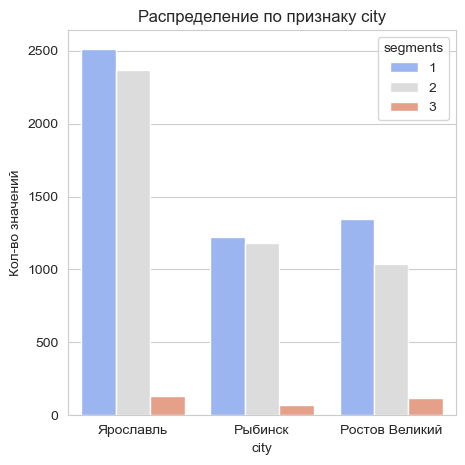

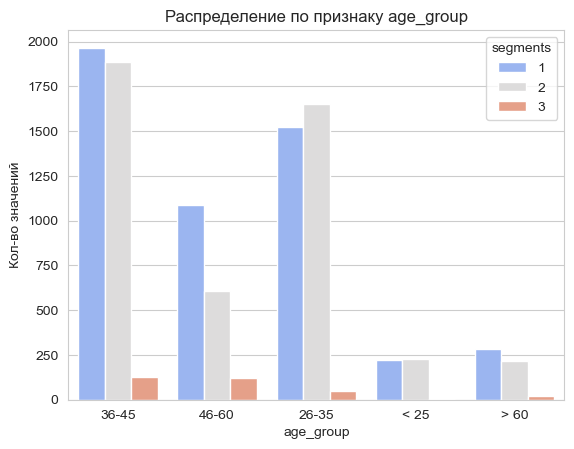

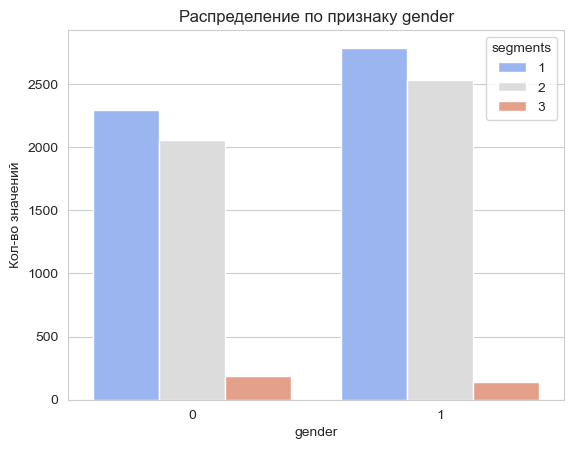

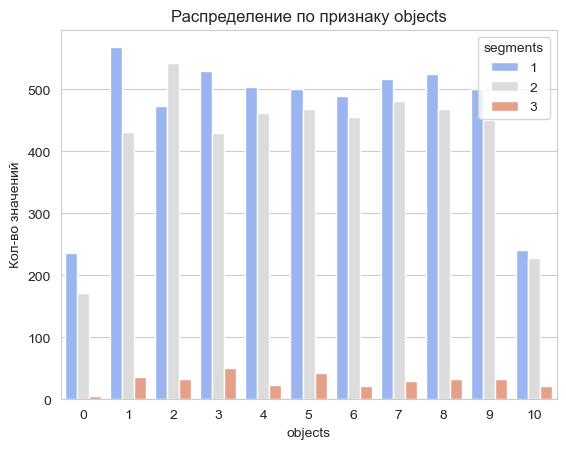

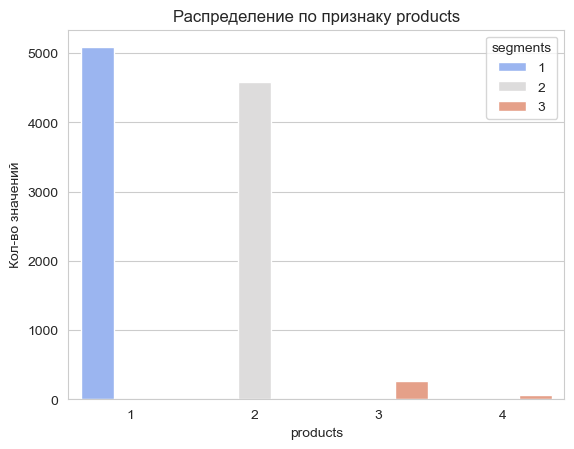

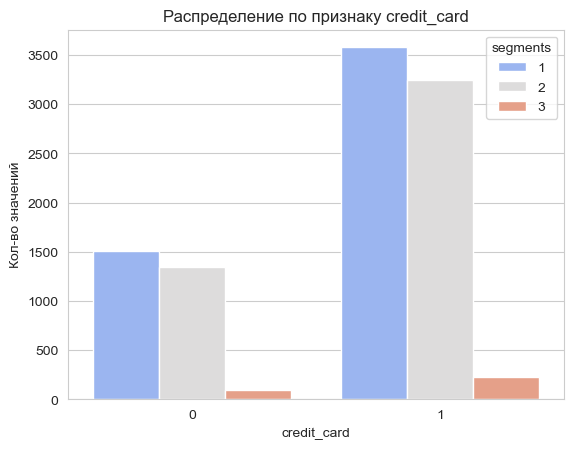

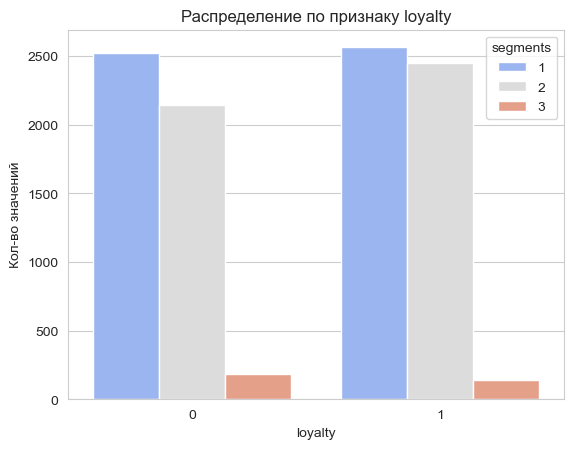

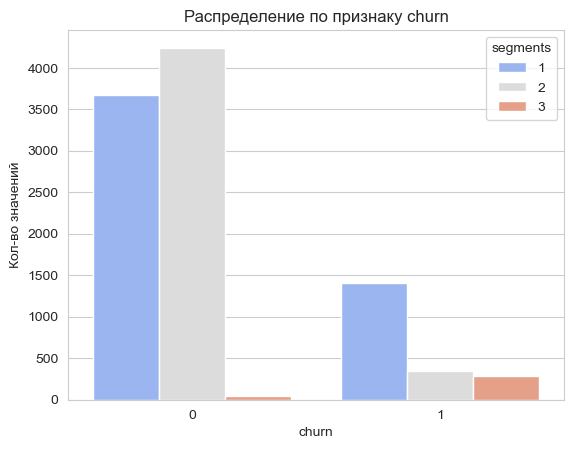

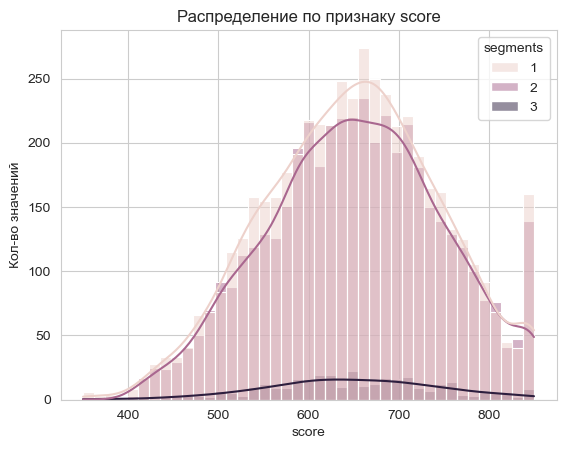

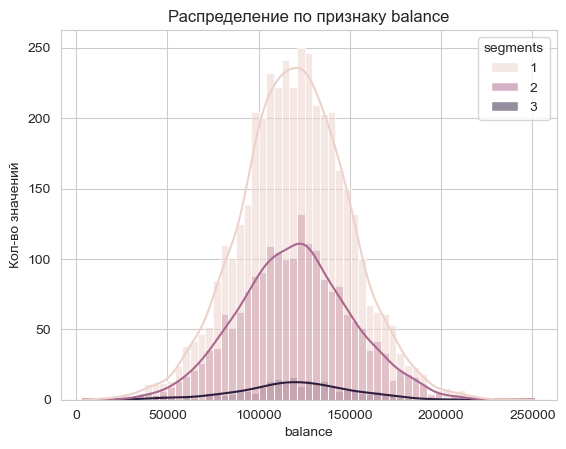

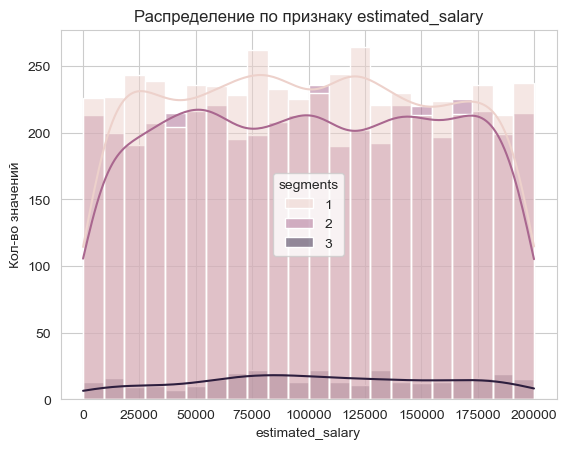

In [31]:
# визуализируем распределение с делением по сегментам
d_list = ['city', 'age_group', 'gender', 'objects', 'products', 'credit_card', 'loyalty', 'churn']
c_list = ['score',  'balance', 'estimated_salary']
graf(df, d_list, c_list, hue='segments')  

Расммотрим детальнее распределение относительно оттока, для этого построим диаграммы разброса

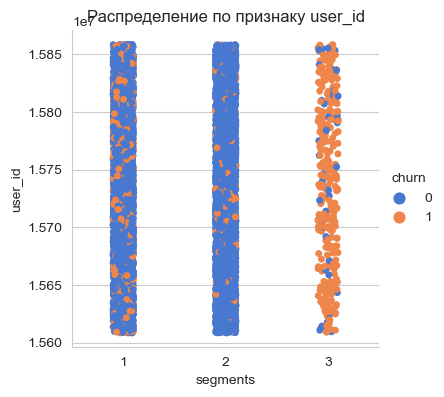

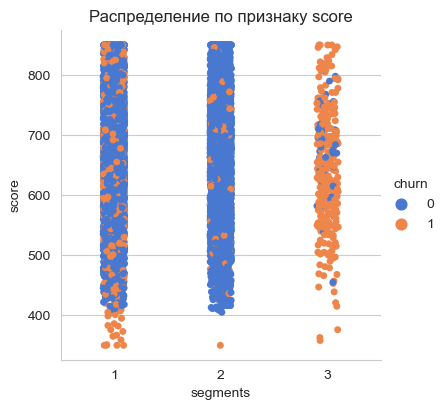

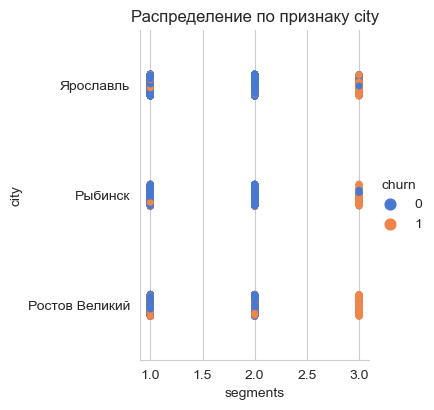

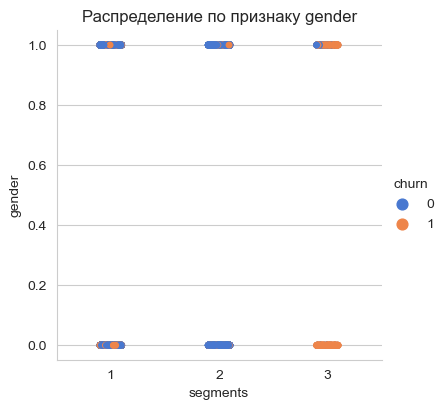

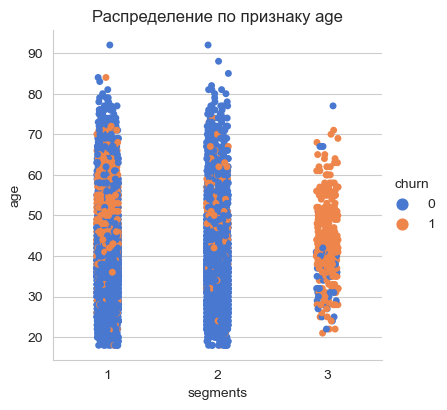

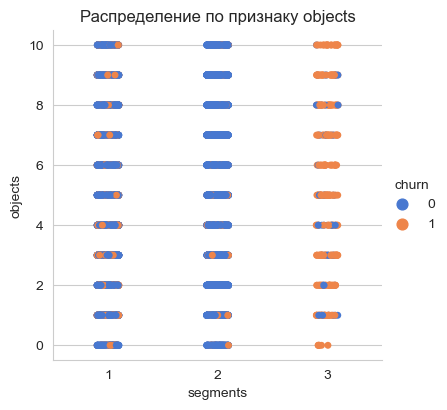

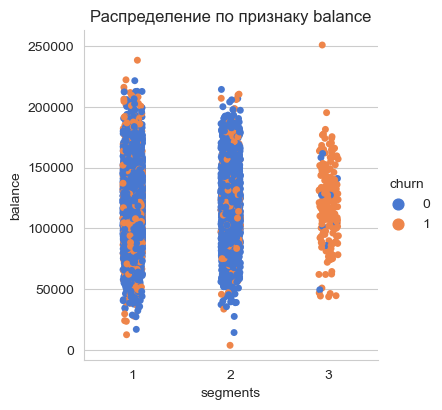

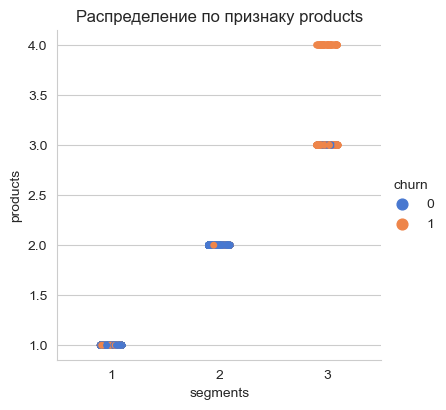

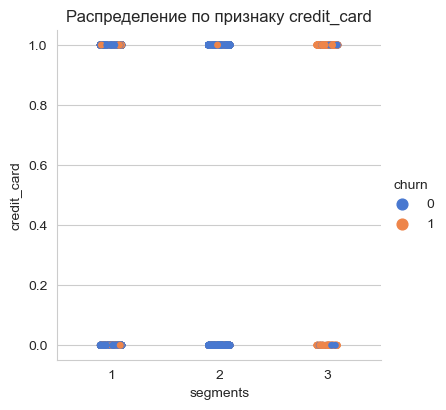

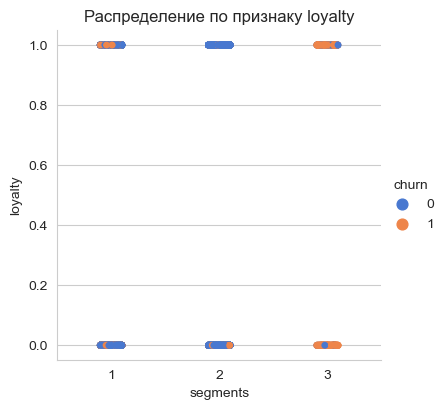

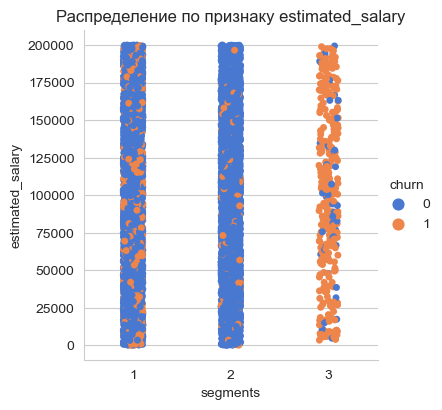

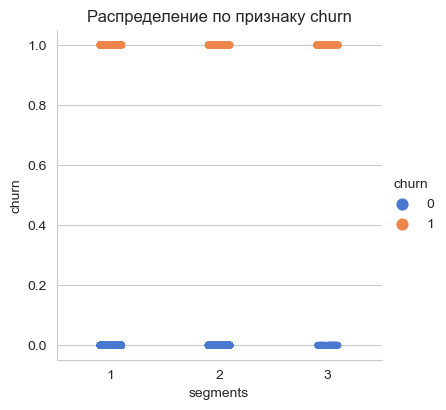

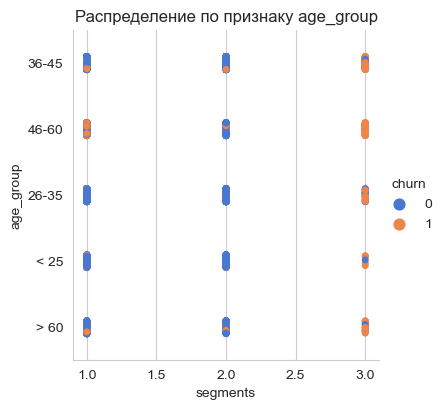

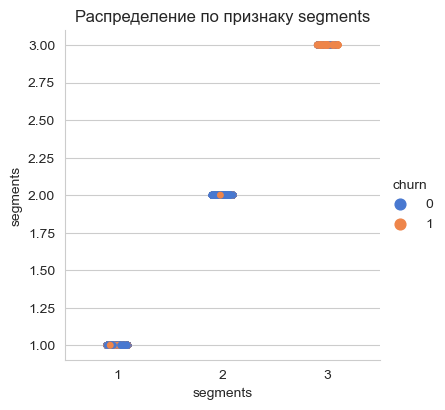

In [72]:
for column in df.columns.values: 
    sns.catplot(
        data=df, y=column, x='segments', hue='churn',
        height=4, palette='muted'
    ) 
    
    plt.title(f'Распределение по признаку {column}', fontsize = 12)
    plt.show()

In [32]:
# построим сводную табл для среднего и медианого занчения
pd.pivot_table(df, index='segments',
                    aggfunc={'age': np.median,
                             'gender': np.mean,
                             'objects': np.mean,
                             'credit_card': np.mean,
                             'loyalty': np.mean,
                             'churn': np.mean,
                             'score': np.median,
                             'balance': np.mean,
                             'estimated_salary': np.median,
                             'user_id': 'nunique'
                             })

,age,balance,churn,credit_card,estimated_salary,gender,loyalty,objects,score,user_id
segments,,,,,,,,,,
1,38,119894.163723,0.277144,0.703777,99226.830,0.548387,0.504131,4.974626,651,5084
2,36,119660.944362,0.075817,0.707190,100738.855,0.551198,0.532898,5.051852,653,4590
3,43,120074.314953,0.858896,0.708589,103874.670,0.426380,0.435583,5.058282,650,326


### Вывод 

**Сегмент 3** - клиенты, которые пользуются 3-4 продуктами
- пользуются 3% клиентов, самый малочисленный сегмент по кол-ву пользователей
- характеризуются высоким коэффициентом оттока
- усредненный портрет клиента: женщина 43 лет, скорее всего неактивный пользователь, с балансом 120 тыс. у.е и доходом 104 тыс. у.е. 

**Сегмент 2** - клиенты, которые пользуются 2 продуктами
- пользуются 46% клиентов, второй по многочислености сегмент
- пользуется большей популярностью в Ярославле, в остальных городах рапределен равномерно 
- самый низкий показатель оттока среди трех сегментов
- усредненный портрет клиента: мужчина 36-45 лет, активный пользователь и имеет кредитную карту, с балансом 119 тыс. и доходом 100 тыс.

**Сегмент 1** - клиенты, которые пользуются 1 продуктом
- пользуются 51% клиентов, самый многочисленный сегмент
- популярен в Ярославле, в остальных городах рапределен почти равномерно
- имеет чуть больше оттока в сравнение со 2 сегментом
- усредненный портрет клиента: мужчина 36-45 лет, имеет кредитную карту, баланс 119 тыс. и доход 99 тыс. 

В целом видно, что кол-во используемых продуктов является ключевой характеристикой, по которой можно судить, с какой вероятностью клиент останется в банке или уйдет. Самая лояльная группа - это клиенты с двумя продуктами, в зоне риска находятся клиенты 3 сегмента (3 и 4 продукта).

## 5. Статистическая проверка гипотез

### Гипотеза №1

Гипотеза: есть ли статистически значемое различие в среднем возрасте между теми клиентами, которые пользуются двумя продуктами банка, и теми, которые пользуются одним.

Сформулируем нулевую и альтернативную гипотезы:

    H_0: Статистически значимых различий в среднем возрасте между клиентами, которые пользуются двумя продуктами банка, и теми, которые пользуются одним, нет.
    H_1: Статистически значимые различия в среднем возрасте между клиентами, которые пользуются двумя продуктами банка, и теми, которые пользуются одним, есть.

In [33]:
# создадим две выборки 
age_1 = df.query('products == 1')['age']
age_2 = df.query('products == 2')['age']

In [34]:
# смоторим на показатели по выборкам
age_1.describe()

count    5084.000000
mean       39.673092
std        10.659566
min        18.000000
25%        32.000000
50%        38.000000
75%        45.000000
max        92.000000
Name: age, dtype: float64

In [35]:
age_2.describe()

count    4590.000000
mean       37.753595
std        10.145663
min        18.000000
25%        31.000000
50%        36.000000
75%        42.000000
max        92.000000
Name: age, dtype: float64

Видим, что показатели среднего и стандартного отклонения по выборкам приблизительно равны. Посмотрим на распределение и выбросы

In [36]:
# функция для графиков

# распределение
def d_plot (data, x, xlabel):
    
    sns.displot(
        data=data, x=x, col='products', kde=True, color="darkblue", height=5, facet_kws=dict(margin_titles=True)
    ).set(xlabel=xlabel, ylabel='Кол-во клиентов')
    plt.show()

# выбросы    
def b_plot (data, y, ylabel):
    
    sns.boxplot(y=y, data=data, x ='products', palette='Purples').set( 
            ylabel=ylabel)
    plt.show()

Распределение по возрасту клиентов для 1 и 2 продуктов


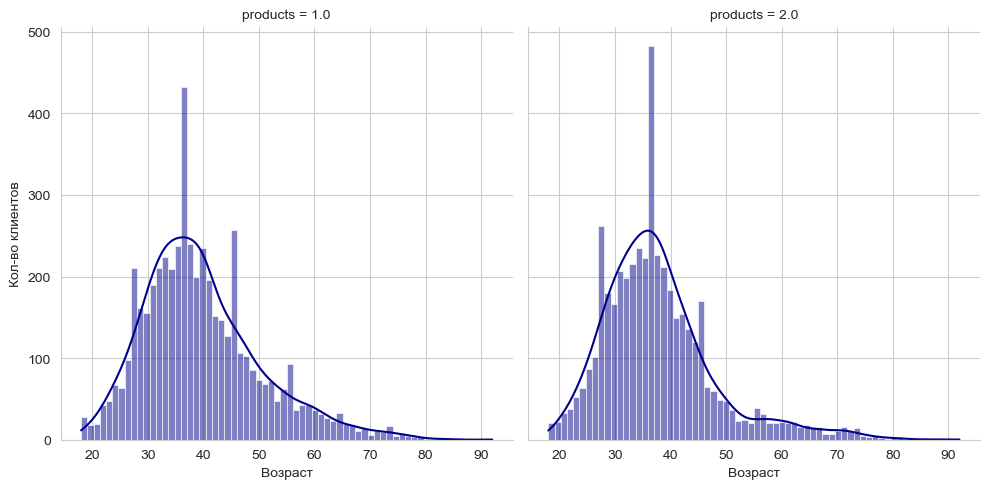

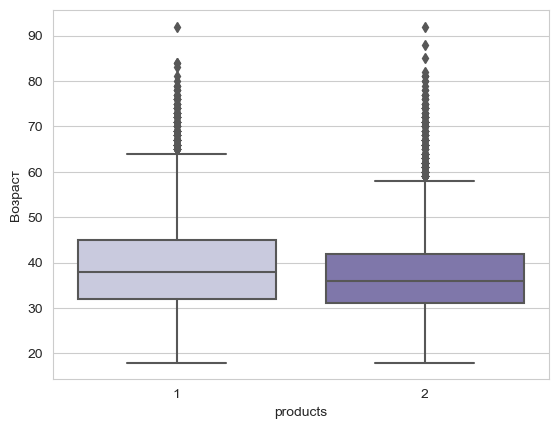

In [37]:
print('Распределение по возрасту клиентов для 1 и 2 продуктов')

d_plot(df.query('products in [1,2]'), df['age'], 'Возраст')
b_plot(df.query('products in [1,2]'), df['age'], 'Возраст')

Выбросы есть, но ранее мы решили их не удалять. Выборки достаточно большие и независимы друг от друга, их std сопоставимы. Проверять гипотезу будем c помощью t-критерия Стьюдента. Критическим уровнем значимости (alpha) примем значение 0,001, так как у нас большая выборка.

In [38]:
alpha = .001
result = st.ttest_ind(age_1, age_2)

print('p-значение:', result.pvalue)

if result.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

p-значение: 1.730821607368763e-19
Отвергаем нулевую гипотезу


Так как принятый критический уровень вероятности 0,001, нулевую гипотезу отвергаем как маловероятную.
Нулевая гипотеза отвергнута, значит в среднем возрасте клиентов, пользующихся 1 и 2 продуктами, есть различия.

### Гипотеза №2

Гипотеза: есть ли различия в среднем доходе между теми клиентами, которые пользуются двумя продуктами банка, и теми, которые пользуются одним. 

Сформулируем нулевую и альтернативную гипотезы: 

    H_0: Статистически значимых различий в среднем доходе между теми клиентами, которые пользуются двумя продуктами банка, и теми, которые пользуются одним, нет.
    H_1: Статистически значимые различия в среднем доходе между теми клиентами, которые пользуются двумя продуктами банка, и теми, которые пользуются одним, есть.

In [39]:
# создадим две выборки 
salary_1 = df.query('products == 1')['estimated_salary']
salary_2 = df.query('products == 2')['estimated_salary']

In [40]:
# смоторим на показатели по выборкам
salary_1.describe()

count      5084.000000
mean      99487.256851
std       57363.626412
min          11.580000
25%       50414.515000
50%       99226.830000
75%      148212.695000
max      199970.740000
Name: estimated_salary, dtype: float64

In [41]:
salary_2.describe()

count      4590.000000
mean     100452.012821
std       57790.799984
min          90.070000
25%       50797.287500
50%      100738.855000
75%      150151.460000
max      199992.480000
Name: estimated_salary, dtype: float64

Видим, что показатели среднего и стандартного отклонения по выборкам приблизительно равны. Посмотрим на распределение и выбросы

Распределение дохода клиентов для 1 и 2 продуктов


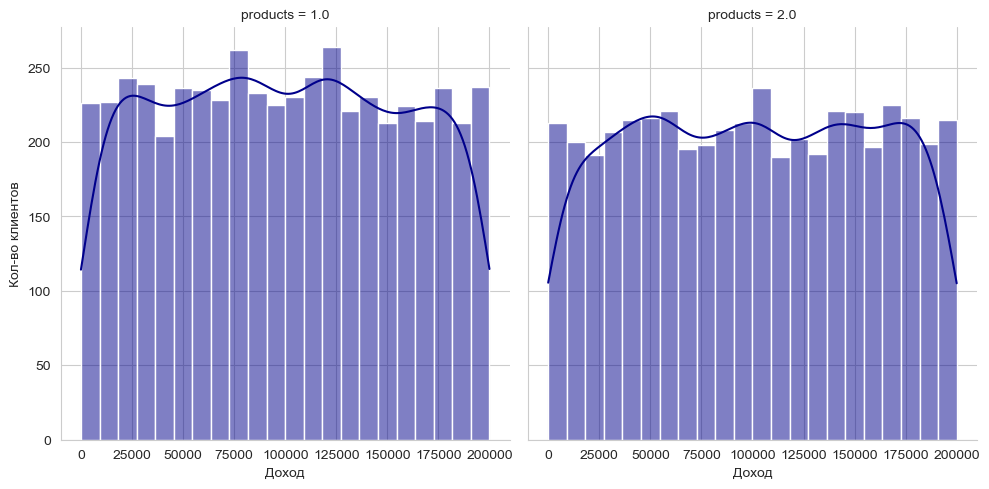

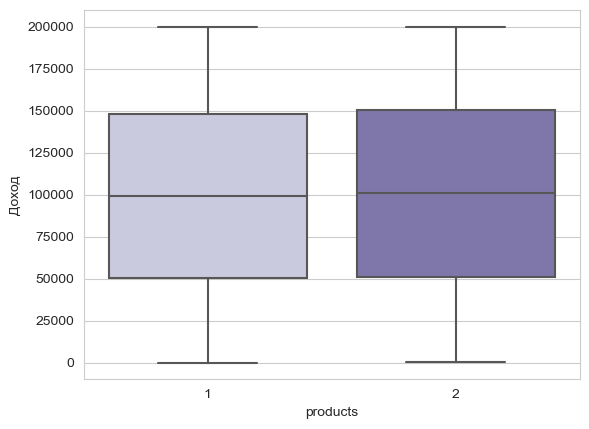

In [42]:
print('Распределение дохода клиентов для 1 и 2 продуктов')

d_plot(df.query('products in [1,2]'), df['estimated_salary'], 'Доход')
b_plot(df.query('products in [1,2]'), df['estimated_salary'], 'Доход')

Выбросов нет. Выборки достаточно большие и независимы друг от друга, их std сопоставимы. Проверять гипотезу будем c помощью t-критерия Стьюдента. Критическим уровнем значимости (alpha) примем значение 0,001, так как у нас большая выборка.

In [43]:
alpha = .001
result = st.ttest_ind(salary_1, salary_2)

print('p-значение:', result.pvalue)

if result.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

p-значение: 0.41047183624949335
Не получилось отвергнуть нулевую гипотезу


Так как принятый критический уровень вероятности 0,001, нулевую гипотезу не отвергаем.
Нулевая гипотеза не отвергнута, значит в доходе клиентов, пользующихся 1 и 2 продуктами, нет различий.

### Вывод

Гипотеза о равенстве среднего дохода у клиентов, пользующихся одним и двумя продуктами, не опровергнута. С большой степенью вероятности в среднем доходы не имеют различий. Напротив, гипотеза о равентсве среднего возраста у клиентов, пользующихся одним и двумя продуктами, опровергнута, значит возраст различается.

## 6. Выводы и рекомендации



**Сегмент 3**

Характеристика: 
- клиенты, которые пользуются 3-4 продуктами
- самый малочисленный сегмент по кол-ву пользователей (3%)
- высокий коэффициентом оттока
- больше клиентов уходит из филиала в Ростове 
- портрет клиента: женщина 43 лет и старше, скорее всего неактивный пользователь, с балансом 120 тыс.у.е и доходом 104 тыс.у.е.

Рекомендации: 
1. Выявить причины неудовлетворенности 3 и 4 продуктами. Скорее всего один из продуктов - кредитная карта, и причинами оттока могут быть невыгодные условия, большая ставка или неадаптивность к современным тенденциям. 
2. Возможно необходимо пересмотреть системы бонусов, которая стимулировала бы использование кредитной карты и не позволяла уходить пользователям в неактивные клиенты.
3. Так как этими продуктами чаще пользуются женщины 45 лет и страрше с высоким доходим, возможно необходимо изменить данные продукты с учетом потребностей именно этой категории клиентов. Например, вклады для пенсионеров или карты с повышенным кэшбэком в категории «Аптеки».

**Сегмент 2** 

Характеристика: 
- клиенты, которые пользуются 2 продуктами
- второй по многочислености сегмент (46%)
- пользуется большей популярностью в Ярославле
- самый низкий показатель оттока
- портрет клиента: мужчина 36-45 лет, активный пользователь, имеет кредитную карту, с балансом 119 тыс. и доходом 100 тыс.

Рекомендации: тут все прекрасно.

**Сегмент 1**

Характеристика:
- клиенты, которые пользуются 1 продуктом
- самый многочисленный сегмент (51% )
- имеет чуть больше оттока в сравнение со 2 сегментом
- портрет клиента: мужчина 36-45 лет, имеет кредитную карту, баланс 119 тыс. и доход 99 тыс.

Рекомендации:
1. В группе оттока клиенты в возрасте 45-60 лет, возможно стоит обратить внимание и подстроить породукт для этих клиентов, например добавить специальный кешбек или вклад. 
2. Предлагать дополнительные продукты 